In [10]:
from typing import TypedDict
from langgraph.graph import StateGraph

In [11]:
class AgentState(TypedDict):
    message : str

def greeting_node(state : AgentState) -> AgentState:
    """ Simple node that add a greeting message to the state"""
    state["message"] = "Hi " + state["message"] + ", how are you?"
    return state

In [12]:
graph = StateGraph(AgentState)
graph.add_node("first_message",greeting_node)
graph.set_entry_point("first_message")
graph.set_finish_point("first_message")
app = graph.compile()

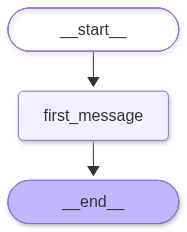

In [13]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [14]:
result = app.invoke({"message" : "sai"})

In [15]:
result["message"]

'Hi sai, how are you?'

In [16]:
class PCA(TypedDict):
    name : str

def student_name(state : PCA) -> PCA:
    """You have  to concatenate the state not replace it"""
    state['name'] = state['name'] + ", you're doing  an amazing job learning Langgraph!"
    return state

In [18]:
g1 = StateGraph(PCA)
g1.add_node("name_student",student_name)
g1.set_entry_point("name_student")
g1.set_finish_point("name_student")
app = g1.compile()

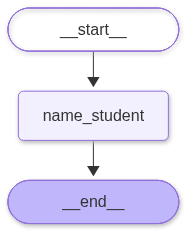

In [20]:
from IPython.display import Image,display
display(Image(app.get_graph().draw_mermaid_png()))

In [22]:
result1 = app.invoke({'name':'bob'})

In [24]:
result1['name']

"bob, you're doing  an amazing job learning Langgraph!"